In [1]:
from datasets import load_dataset

# Login using e.g. `huggingface-cli login` to access this dataset
ds = load_dataset("mteb/imdb")

README.md:   0%|          | 0.00/6.99k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.9MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.2MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/24904 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/24678 [00:00<?, ? examples/s]

In [2]:
ds

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 24904
    })
    test: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 24678
    })
})

# Examples

In [78]:
positive = ds['train'].filter(lambda x: x['label'] == 1)
negative = ds['train'].filter(lambda x: x['label'] == 0)

print('Positive examples')
for i, example in enumerate(positive.shuffle(seed=42).select(range(50))):
    print(f'Example {i+1}:\n{example['text']} \nLabel: {example['label']}\n')

Positive examples
Example 1:
The story of this film is truly remarkable. A virus cut loose and only 1% of the human race survived. The only thing we know now is that animals rule the land above and there are posters everywhere that say, "The Twelve Monkeys did it." Thats right, the human race had to hide underground from the sickness that had killed over 500 Billion people. Apparently animals do not contract this disease. Day by day the present scientist try to discover what type of sickness had caused this; how it was created; if nature did it or a mere human being had created it. All they know is that there is are a bunch of animals running around a city above them, the deaths began during 1996-1997, and twelve monkeys have something to do with it. (Or at least thats what the poster says.) So a current convict named James Cole (Bruce Willis) is sent as a "volunteer" to get some samples from above. After he does his "volunteer" work, he is asked to be sent back in time to the year 199

In [114]:
print('Negative examples')
for i, example in enumerate(negative.shuffle(seed=0).select(range(20))):
    print(f'Example {i+1}:\n{example['text']} \nLabel: {example['label']}\n')

Negative examples
Example 1:
I think this would have been a much better film if the Cajuns had been portrayed in a more believable light. My family is from the southeast region of Louisiana and I live in southeast Texas (about 20 miles from Lake Charles). I have never heard the people I grew up around talk like these folks did. The Cajuns were portrayed as backwards rednecks. Most of the Cajuns I know are well educated, proud people and don't sound uneducated at all when they talk the way these people did. All in all it was an OK movie, with great scenery and music. I understand that the writers were from Lake Charles, and have knowledge of the area, but for the love of all things Cajun, please have the actors study the language, live amongst the people you are portraying and get an all around understanding of how they are before you go trying to act like them. In my opinion, when the actors make you believe they are that person, it's a much more enjoyable movie! 
Label: 0

Example 2:


# Labels distribution

In [25]:
train_positive_number = len(ds['train'].filter(lambda x: x['label'] == 1))
train_negative_number = len(ds['train'].filter(lambda x: x['label'] == 0))

test_positive_number = len(ds['test'].filter(lambda x: x['label'] == 1))
test_negative_number = len(ds['test'].filter(lambda x: x['label'] == 0))

print(f'Train positive ratio: {round(train_positive_number / (train_positive_number + train_negative_number), 3)}')
print(f'Train negative ratio: {round(train_negative_number / (train_positive_number + train_negative_number), 3)}')

print(f'Test positive ratio: {round(test_positive_number / (test_positive_number + test_negative_number), 3)}')
print(f'Test negative ratio: {round(test_negative_number / (test_positive_number + test_negative_number), 3)}')

Train positive ratio: 0.501
Train negative ratio: 0.499
Test positive ratio: 0.503
Test negative ratio: 0.497


# Length distribution

In [39]:
def length(example):
    example['length'] = len(example['text'])
    return example

ds['train'] = ds['train'].map(length)
ds['test'] = ds['test'].map(length)

Mean length: 1326.376, std: 1004.11, median length: 979.0


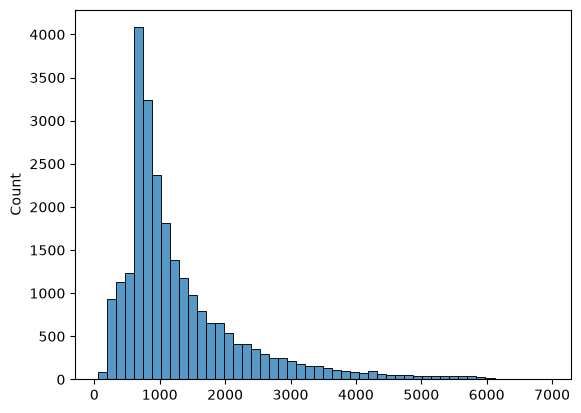

In [63]:
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np


train_lengths = np.array([ex['length'] for ex in ds['train']])
test_lengths = np.array([ex['length'] for ex in ds['test']])

print(f'Mean length: {np.round(train_lengths.mean(), 3)}, std: {np.round(train_lengths.std(), 2)}, median length: {np.median(train_lengths)}')
sns.histplot(train_lengths[train_lengths < 7000], bins=50)
plt.show()


In [77]:
ds.filter(lambda x: '<br' in x['text'])

Filter:   0%|          | 0/24904 [00:00<?, ? examples/s]

Filter:   0%|          | 0/24678 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'label_text', 'length'],
        num_rows: 14615
    })
    test: Dataset({
        features: ['text', 'label', 'label_text', 'length'],
        num_rows: 14351
    })
})

In [105]:
for ex in ds['train'].filter(lambda x: "out of 10" in x['text']).select(range(50)):
    print(ex['text'])

Filter:   0%|          | 0/24904 [00:00<?, ? examples/s]

Pros: Nothing<br /><br />Cons: Everything<br /><br />Plot summary: A female reporter runs into a hitchhiker that tells her stories about the deaths of people that were killed by zombies.<br /><br />Review: Never in my life have I come across a movie as bad The Zombie Chronicles. Filmed on a budget of what looks to be about 20 bucks, TZC is a completely horrible horror movie that relies on lame, forgetable actors whom couldn't act to save their lives and gore that's more gross than frightening. How does a movie like this even get made? Simply put, avoid TZC like a sexually-transmitted disease.<br /><br />My last 2 cents: Humorously enough, this movie was made by a movie company called Brain Damage Films. They're brains must have really been damaged to come up with a craptacular movie like this.<br /><br />My rating: 1 out of 10(If it were up to me, this movie would get the rating of negative bajillion)
1st watched 8/3/2003 - 2 out of 10(Dir-Brad Sykes): Mindless 3-D movie about flesh-ea

In [147]:
ds['train'].filter(lambda x: "two" in x['text']).select(range(20))[1]

{'text': 'Today I found "They All Laughed" on VHS on sale in a rental. It was a really old and very used VHS, I had no information about this movie, but I liked the references listed on its cover: the names of Peter Bogdanovich, Audrey Hepburn, John Ritter and specially Dorothy Stratten attracted me, the price was very low and I decided to risk and buy it. I searched IMDb, and the User Rating of 6.0 was an excellent reference. I looked in "Mick Martin & Marsha Porter Video & DVD Guide 2003" and \x96 wow \x96 four stars! So, I decided that I could not waste more time and immediately see it. Indeed, I have just finished watching "They All Laughed" and I found it a very boring overrated movie. The characters are badly developed, and I spent lots of minutes to understand their roles in the story. The plot is supposed to be funny (private eyes who fall in love for the women they are chasing), but I have not laughed along the whole story. The coincidences, in a huge city like New York, are r